In [54]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [55]:
df = pd.read_csv('insurance.csv')
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


# EDA

In [56]:
df.shape

(1338, 7)

In [57]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [58]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [59]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [60]:
#here our target column will be "charges", all the optimization will be done according to it

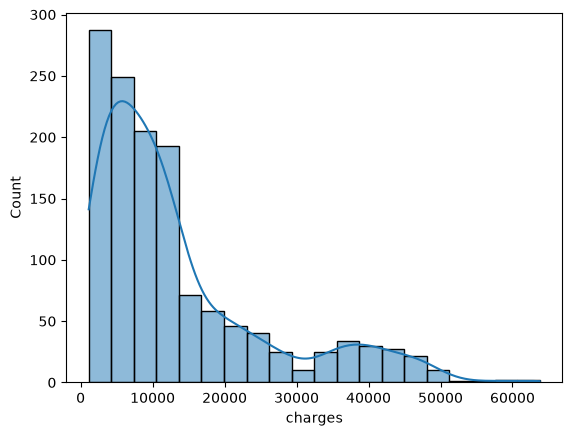

In [61]:
sns.histplot(df['charges'], bins=20, kde=True)
plt.show() #data is heavily left skewed

In [62]:
num_col = df.select_dtypes(include=['int64', 'float64'])
num_col

,age,bmi,children,charges
0,19,27.900,0,16884.92400
1,18,33.770,1,1725.55230
2,28,33.000,3,4449.46200
3,33,22.705,0,21984.47061
4,32,28.880,0,3866.85520
...,...,...,...,...
1333,50,30.970,3,10600.54830
1334,18,31.920,0,2205.98080
1335,18,36.850,0,1629.83350
1336,21,25.800,0,2007.94500


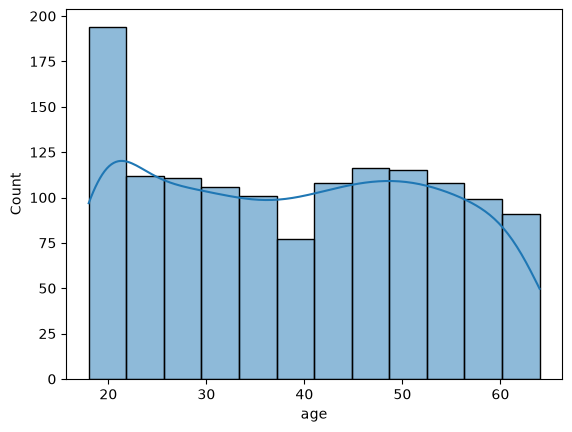

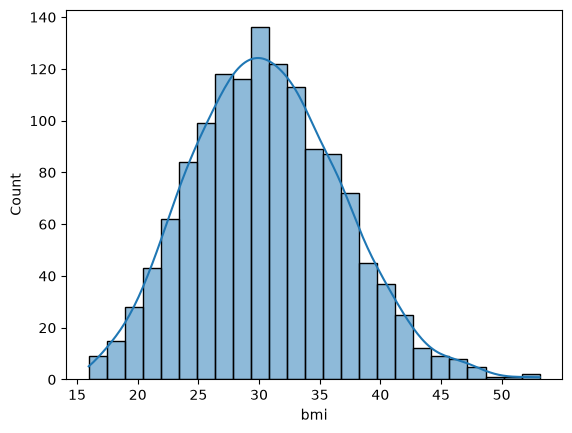

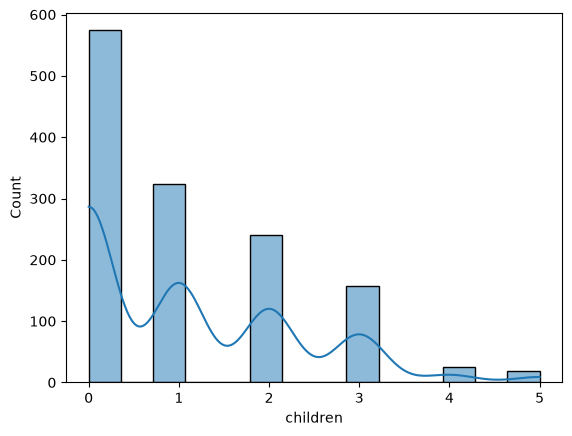

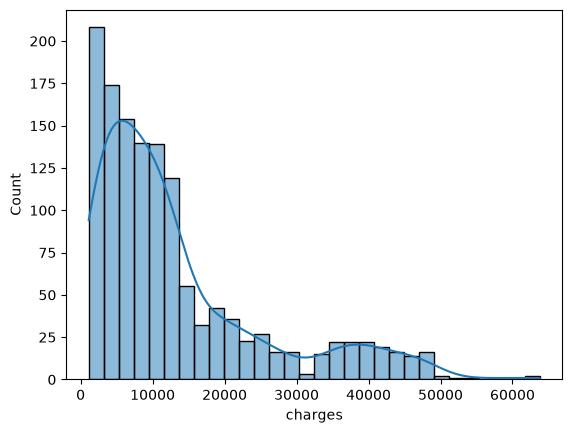

In [63]:
#seeing the distribution for numerical data

for col in num_col:
    sns.histplot(df[col], kde=True)
    plt.show()

In [64]:
#here we will treat children col as categorical bcz there maybe some specific no of childs

In [65]:
#creating a countplot for rest columns to analyze

<Axes: xlabel='children', ylabel='count'>

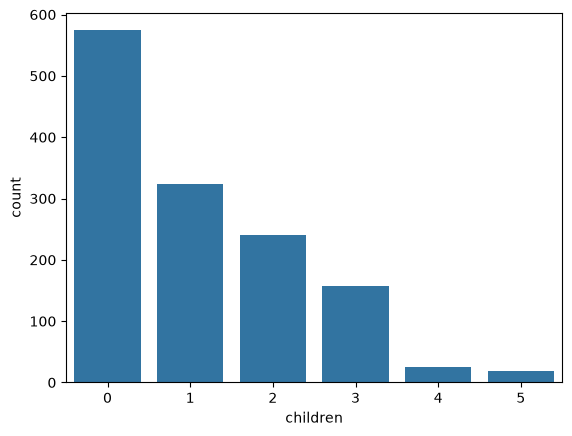

In [66]:
sns.countplot(x=df['children'])

<Axes: xlabel='sex', ylabel='count'>

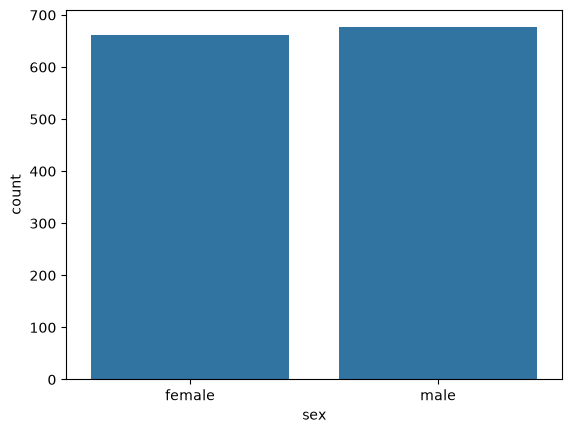

In [67]:
sns.countplot(x=df['sex'])

<Axes: xlabel='region', ylabel='count'>

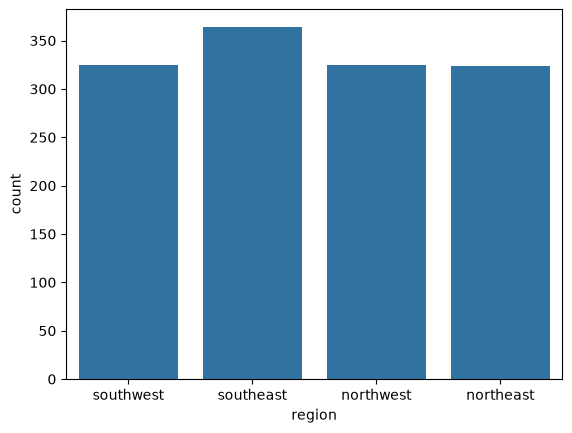

In [68]:
sns.countplot(x=df['region'])

<Axes: xlabel='smoker', ylabel='count'>

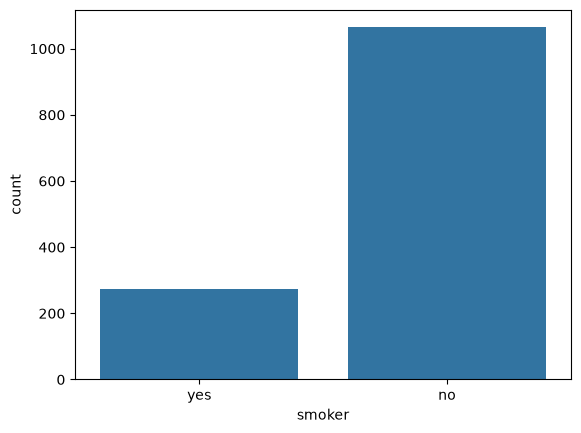

In [69]:
sns.countplot(x=df['smoker'])

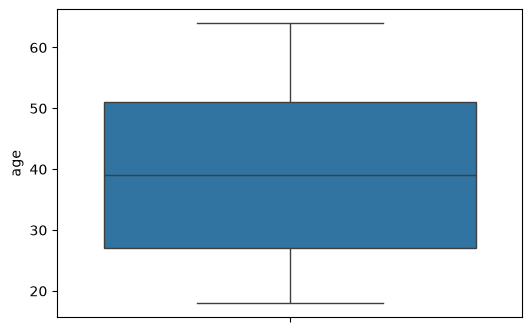

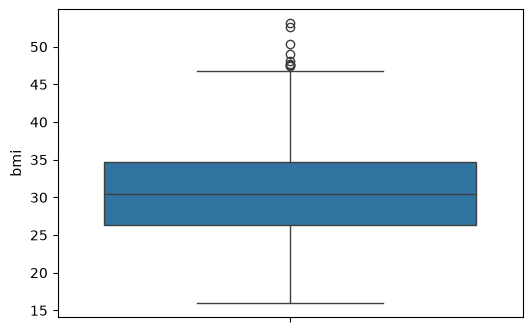

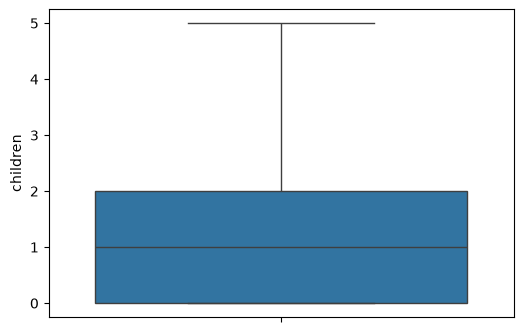

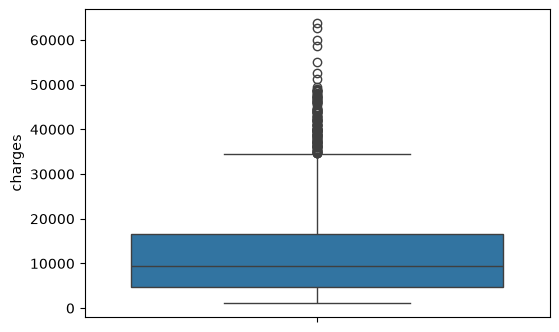

In [70]:
for col in num_col:
    plt.figure(figsize=(6,4))
    sns.boxplot(df[col])
    plt.show()

<Axes: >

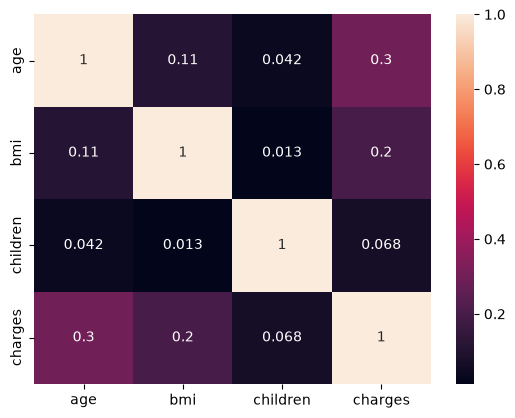

In [71]:
#this shows all the correlations btw the data columns
sns.heatmap(df.corr(numeric_only=True), annot=True)

# Data cleaning and preprocessing

Encoding and cleaning preprecessed data comes under this category.

In [72]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [73]:
df.shape
df.drop_duplicates(inplace=True)
df.shape

(1337, 7)

In [74]:
#LabelEncoding and renaming object columns
#can also use .map() to label encode these columns

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

obj_cols = ['sex', 'smoker']
for col in obj_cols:
    df[col] = le.fit_transform(df[col])

df.rename(columns = {
    'sex' : 'is_male',
    'smoker' : 'is_smoker'
}, inplace=True)

df

,age,is_male,bmi,children,is_smoker,region,charges
0,19,0,27.900,0,1,southwest,16884.92400
1,18,1,33.770,1,0,southeast,1725.55230
2,28,1,33.000,3,0,southeast,4449.46200
3,33,1,22.705,0,0,northwest,21984.47061
4,32,1,28.880,0,0,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,1,30.970,3,0,northwest,10600.54830
1334,18,0,31.920,0,0,northeast,2205.98080
1335,18,0,36.850,0,0,southeast,1629.83350
1336,21,0,25.800,0,0,southwest,2007.94500


In [75]:
df.nunique()

age            47
is_male         2
bmi           548
children        6
is_smoker       2
region          4
charges      1337
dtype: int64

In [76]:
#Applying OneHot encoding to region column

df = pd.get_dummies(df, columns=['region'], drop_first=True)
df = df.astype(int)
df

,age,is_male,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest
0,19,0,27,0,1,16884,0,0,1
1,18,1,33,1,0,1725,0,1,0
2,28,1,33,3,0,4449,0,1,0
3,33,1,22,0,0,21984,1,0,0
4,32,1,28,0,0,3866,1,0,0
...,...,...,...,...,...,...,...,...,...
1333,50,1,30,3,0,10600,1,0,0
1334,18,0,31,0,0,2205,0,0,0
1335,18,0,36,0,0,1629,0,1,0
1336,21,0,25,0,0,2007,0,0,1


# Feature Engineering and Extraction
Creating new columns from existing column is called feature
engg.

Selecting highly correlated features for ML model is called
Feature Selection or Extraction

<Axes: xlabel='bmi', ylabel='Count'>

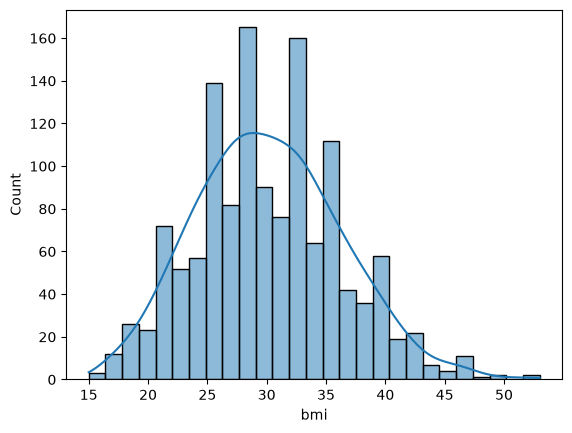

In [77]:
sns.histplot(x=df['bmi'], kde=True)

In [78]:
df['bmi_categories'] = pd.cut(
    df['bmi'],#column to make bin out of
    bins=[0, 18.5, 24.9, 29.9, np.inf],
    labels=['Underweight', 'Normal', 'Overweight', 'Obesity'],
)

In [79]:
#encoding and type casting for 'bmi_category'

df= pd.get_dummies(df, columns=['bmi_categories'], drop_first=True)
df.head()

,age,is_male,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_categories_Normal,bmi_categories_Overweight,bmi_categories_Obesity
0,19,0,27,0,1,16884,0,0,1,False,True,False
1,18,1,33,1,0,1725,0,1,0,False,False,True
2,28,1,33,3,0,4449,0,1,0,False,False,True
3,33,1,22,0,0,21984,1,0,0,True,False,False
4,32,1,28,0,0,3866,1,0,0,False,True,False


In [80]:
df = df.astype(int)
df.head()

,age,is_male,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_categories_Normal,bmi_categories_Overweight,bmi_categories_Obesity
0,19,0,27,0,1,16884,0,0,1,0,1,0
1,18,1,33,1,0,1725,0,1,0,0,0,1
2,28,1,33,3,0,4449,0,1,0,0,0,1
3,33,1,22,0,0,21984,1,0,0,1,0,0
4,32,1,28,0,0,3866,1,0,0,0,1,0


# Feature Scaling
Getting scattered values in btw std variance lvl we use scaling.

In [81]:
df.columns

Index(['age', 'is_male', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northwest', 'region_southeast', 'region_southwest',
       'bmi_categories_Normal', 'bmi_categories_Overweight',
       'bmi_categories_Obesity'],
      dtype='str')

In [82]:
from sklearn.preprocessing import StandardScaler
cols = ['age','bmi','children']
ss = StandardScaler()
df[cols] = ss.fit_transform(df[cols])
df.head()

,age,is_male,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_categories_Normal,bmi_categories_Overweight,bmi_categories_Obesity
0,-1.440418,0,-0.517949,-0.909234,1,16884,0,0,1,0,1,0
1,-1.511647,1,0.462463,-0.079442,0,1725,0,1,0,0,0,1
2,-0.799350,1,0.462463,1.580143,0,4449,0,1,0,0,0,1
3,-0.443201,1,-1.334960,-0.909234,0,21984,1,0,0,1,0,0
4,-0.514431,1,-0.354547,-0.909234,0,3866,1,0,0,0,1,0


# Feature Selection
Find the features which highly correlates with target column. 

-> Using Pearson Correlation

In [83]:
from scipy.stats import pearsonr

#list of features to check against the target column for correlation 

selected_col = ['age', 'is_male', 'bmi', 'children', 'is_smoker',
       'region_northwest', 'region_southeast', 'region_southwest',
       'bmi_categories_Normal', 'bmi_categories_Overweight',
       'bmi_categories_Obesity']

selected_col

['age',
 'is_male',
 'bmi',
 'children',
 'is_smoker',
 'region_northwest',
 'region_southeast',
 'region_southwest',
 'bmi_categories_Normal',
 'bmi_categories_Overweight',
 'bmi_categories_Obesity']

In [84]:
correlation = {
    feature : pearsonr(df[feature], df['charges'])[0]
    for feature in selected_col
}

correlation_df = pd.DataFrame(list(correlation.items()), columns=['Features', 'Correlation'])
correlation_df.sort_values(by='Correlation', ascending=False)

,Features,Correlation
4,is_smoker,0.787234
0,age,0.298309
10,bmi_categories_Obesity,0.200348
2,bmi,0.196236
6,region_southeast,0.073577
3,children,0.067390
1,is_male,0.058046
5,region_northwest,-0.038695
7,region_southwest,-0.043637
8,bmi_categories_Normal,-0.104042


-> Using kaiSquared test
 
To find the correlation between categorical columns

In [85]:
cat_col = ['is_male','is_smoker','region_northwest', 'region_southeast', 'region_southwest',
           'bmi_categories_Normal', 'bmi_categories_Overweight',
                  'bmi_categories_Obesity']


In [86]:
from scipy.stats import chi2_contingency
alpha = 0.05

df['charges_bins'] = pd.qcut(df['charges'], q=4, labels=False)
chi2_result = {}

for col in  cat_col:
    contigency = pd.crosstab(df[col], df['charges_bins'])
    chi2_stat, p_val, _, _= chi2_contingency(contigency)
    decision = "Reject Null (keep feature)" if p_val < alpha else "Accept Null (Drop feature)"
    chi2_result[col] = {
        'chi2_statistics' : chi2_stat,
        'p_value' : p_val,
        'Decision' : decision
    }


chi2_df = pd.DataFrame(chi2_result).T
chi2_df = chi2_df.sort_values(by='p_value')
chi2_df

,chi2_statistics,p_value,Decision
is_smoker,848.219178,0.0,Reject Null (keep feature)
region_southeast,15.998167,0.001135,Reject Null (keep feature)
is_male,10.258784,0.01649,Reject Null (keep feature)
bmi_categories_Obesity,8.515711,0.036473,Reject Null (keep feature)
region_southwest,5.091893,0.165191,Accept Null (Drop feature)
bmi_categories_Overweight,4.25149,0.235557,Accept Null (Drop feature)
bmi_categories_Normal,3.708088,0.29476,Accept Null (Drop feature)
region_northwest,1.13424,0.768815,Accept Null (Drop feature)


In [87]:
df = df[['age', 'is_male', 'is_smoker', 'region_southeast', 'bmi_categories_Obesity', 'bmi', 'children', 'charges']]
df

,age,is_male,is_smoker,region_southeast,bmi_categories_Obesity,bmi,children,charges
0,-1.440418,0,1,0,0,-0.517949,-0.909234,16884
1,-1.511647,1,0,1,1,0.462463,-0.079442,1725
2,-0.799350,1,0,1,1,0.462463,1.580143,4449
3,-0.443201,1,0,0,0,-1.334960,-0.909234,21984
4,-0.514431,1,0,0,0,-0.354547,-0.909234,3866
...,...,...,...,...,...,...,...,...
1333,0.767704,1,0,0,1,-0.027743,1.580143,10600
1334,-1.511647,0,0,0,1,0.135659,-0.909234,2205
1335,-1.511647,0,0,1,1,0.952670,-0.909234,1629
1336,-1.297958,0,0,0,0,-0.844753,-0.909234,2007


# Log Transformation in Target column - charges

In [88]:
df['Log_charges'] = np.log(df['charges'])
df

,age,is_male,is_smoker,region_southeast,bmi_categories_Obesity,bmi,children,charges,Log_charges
0,-1.440418,0,1,0,0,-0.517949,-0.909234,16884,9.734122
1,-1.511647,1,0,1,1,0.462463,-0.079442,1725,7.452982
2,-0.799350,1,0,1,1,0.462463,1.580143,4449,8.400435
3,-0.443201,1,0,0,0,-1.334960,-0.909234,21984,9.998070
4,-0.514431,1,0,0,0,-0.354547,-0.909234,3866,8.259976
...,...,...,...,...,...,...,...,...,...
1333,0.767704,1,0,0,1,-0.027743,1.580143,10600,9.268609
1334,-1.511647,0,0,0,1,0.135659,-0.909234,2205,7.698483
1335,-1.511647,0,0,1,1,0.952670,-0.909234,1629,7.395722
1336,-1.297958,0,0,0,0,-0.844753,-0.909234,2007,7.604396


<Axes: xlabel='Log_charges', ylabel='Count'>

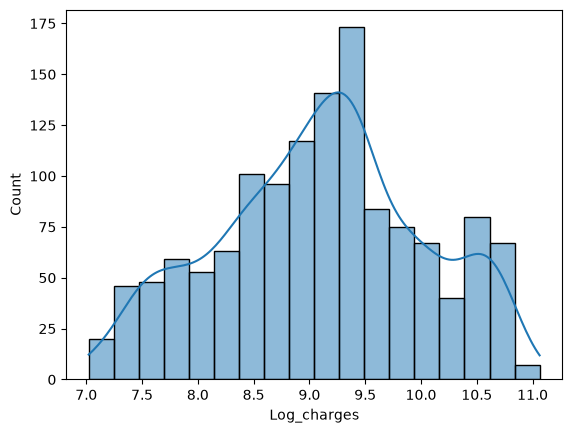

In [89]:
sns.histplot(df['Log_charges'], kde=True)

# Train test split

In [90]:
y = df['Log_charges']
X = df.drop(['Log_charges', 'charges'], axis=1)

y
X

,age,is_male,is_smoker,region_southeast,bmi_categories_Obesity,bmi,children
0,-1.440418,0,1,0,0,-0.517949,-0.909234
1,-1.511647,1,0,1,1,0.462463,-0.079442
2,-0.799350,1,0,1,1,0.462463,1.580143
3,-0.443201,1,0,0,0,-1.334960,-0.909234
4,-0.514431,1,0,0,0,-0.354547,-0.909234
...,...,...,...,...,...,...,...
1333,0.767704,1,0,0,1,-0.027743,1.580143
1334,-1.511647,0,0,0,1,0.135659,-0.909234
1335,-1.511647,0,0,1,1,0.952670,-0.909234
1336,-1.297958,0,0,0,0,-0.844753,-0.909234


In [91]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print(f'X train shape : {X_train.shape}')
print(f'y train shape : {y_train.shape}')
print(f'X test shape : {X_test.shape}')
print(f'y test shape : {y_test.shape}')

X train shape : (1069, 7)
y train shape : (1069,)
X test shape : (268, 7)
y test shape : (268,)


# Linear Regression

In [92]:
#model training
from sklearn.linear_model import LinearRegression
reg = LinearRegression()
reg.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ 0.48,-0.07, 1.54,..., 0.11, 0.03, 0.12]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['age','is_male','is_smoker',...,'bmi_categories_Obesity','bmi','children']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,8.786
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [ ]:
y_pred1 = reg.predict(X_test)
y_pred1[:5]

array([ 8.89302696,  8.70088433,  9.51713672, 10.29109423,  8.6019632 ])

# Model Evaluation

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
print(reg.score(X_test, y_test)) #provides r2 value

r2 = r2_score(y_test, y_pred1)
mse = mean_squared_error(y_test, y_pred1)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred1)

print(f"R² Score: {r2:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")

0.8228425048411976
R² Score: 0.8228
MSE: 0.1645
RMSE: 0.4055
MAE: 0.2678


# Actual Vs Predicted values

In [ ]:
compare = pd.DataFrame({
    'Actual' : y_test,
    'Predicted' : y_pred1
})
compare.head()

,Actual,Predicted
900,9.069698,8.893027
1064,8.649624,8.700884
1256,9.344522,9.517137
298,10.564783,10.291094
237,8.403576,8.601963


# Rigde Regression


In [96]:
from sklearn.linear_model import Ridge

clf = Ridge(alpha=1.0)
clf.fit(X_train, y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [97]:
y_pred2 = clf.predict(X_test)
y_pred2[:5]

array([ 8.89486969,  8.70269735,  9.5175329 , 10.28390764,  8.60506784])

In [98]:
r2 = r2_score(y_test, y_pred2)
mse = mean_squared_error(y_test, y_pred2)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred2)

print(f"R² Score: {r2:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")

R² Score: 0.8225
MSE: 0.1648
RMSE: 0.4059
MAE: 0.2686


# Lasso Regression


In [100]:
from sklearn.linear_model import Lasso

ls = Lasso(alpha=0.1)
ls.fit(X_train, y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.1
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [101]:
y_pred3 = ls.predict(X_test)
y_pred3[:5]

array([9.15433386, 8.70518398, 9.28131906, 9.62712491, 8.71147769])

In [102]:
r2 = r2_score(y_test, y_pred3)
mse = mean_squared_error(y_test, y_pred3)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred3)

print(f"R² Score: {r2:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")

R² Score: 0.6866
MSE: 0.2909
RMSE: 0.5394
MAE: 0.3798


# Saving model to use outside the system 


In [103]:
import joblib

# Assuming 'model' is your trained ML pipeline or estimator (e.g., LinearRegression)
joblib.dump(reg, 'linear_regression_model.pkl')
print("Model saved successfully as a .pkl file!")

Model saved successfully as a .pkl file!
